## 1. Imports and setup ##

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from opa import array_intensity, find_peaks

wl = 1.55e-6          # wavelength: 1550 nm
N = 16                # number of emitters
theta = np.radians(np.linspace(-90, 90, 3601))

## 2. Steering ##

unsteered: peak at 0.00°
steered to 30°: peak at 30.00°


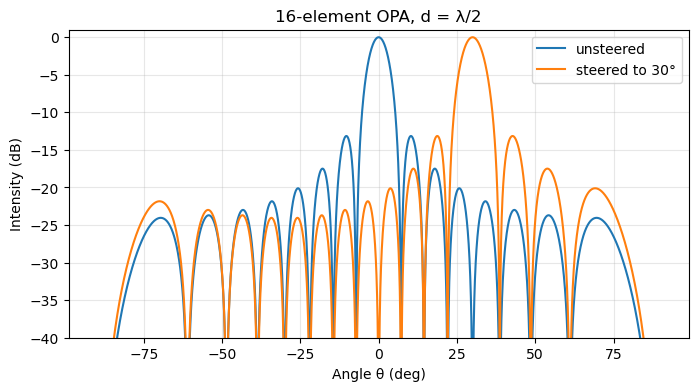

In [3]:
d = wl / 2
target = np.radians(30)
dphi = 2 * np.pi * d / wl * np.sin(target)

plt.figure(figsize=(8, 4))
for dp, label in [(0, "unsteered"), (dphi, "steered to 30°")]:
    I = array_intensity(theta, N, d, wl, dp)
    plt.plot(np.degrees(theta), 10 * np.log10(I + 1e-12), label=label)
    print(f"{label}: peak at {np.degrees(theta[I.argmax()]):.2f}°")

plt.ylim(-40, 1)
plt.xlabel("Angle θ (deg)"); plt.ylabel("Intensity (dB)")
plt.title(f"{N}-element OPA, d = λ/2")
plt.legend(); plt.grid(alpha=0.3); plt.show()

We see that the steered main lobe is wider. Add code to quantify this.

## 3. Sidelobe check ##

In [4]:
I = array_intensity(theta, N, wl / 2, wl, 0)
angles, vals = find_peaks(theta, I)
print(f"Strongest sidelobe: {10*np.log10(np.sort(vals)[-2]):.1f} dB")

Strongest sidelobe: -13.1 dB


## 4. Your first grating lobe ## 

Strong beams at: [-30.  30.] deg


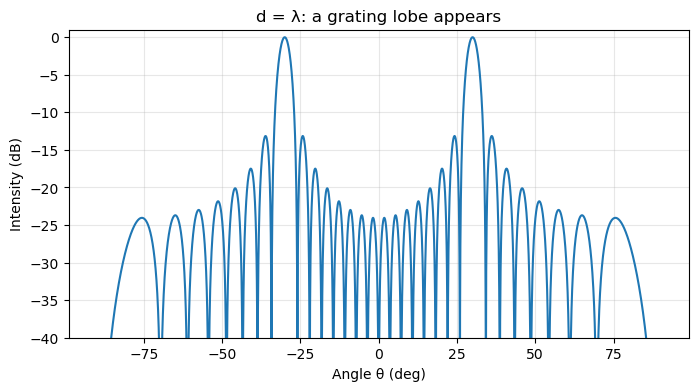

In [5]:
d = wl                                # spacing = one wavelength
dphi = 2 * np.pi * d / wl * np.sin(np.radians(30))
I = array_intensity(theta, N, d, wl, dphi)

angles, vals = find_peaks(theta, I, threshold=0.5)
print("Strong beams at:", np.round(angles, 1), "deg")

plt.figure(figsize=(8, 4))
plt.plot(np.degrees(theta), 10 * np.log10(I + 1e-12))
plt.ylim(-40, 1)
plt.xlabel("Angle θ (deg)"); plt.ylabel("Intensity (dB)")
plt.title("d = λ: a grating lobe appears")
plt.grid(alpha=0.3); plt.show()

## Efficiency ##

First lets investigate D = lambda/2:

Beam efficiency (d = λ/2, N = 16, steered to 30°): 0.904


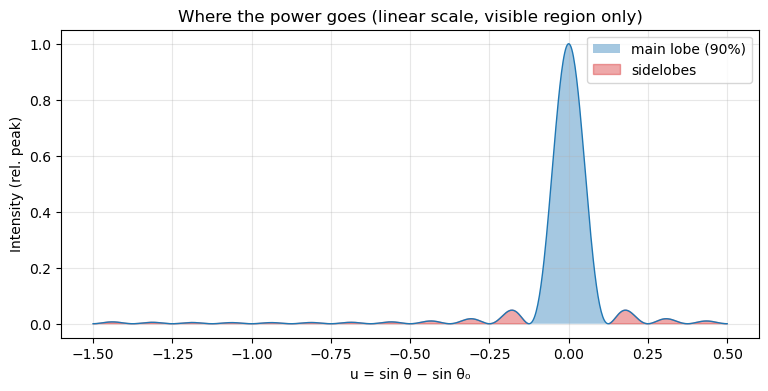

In [9]:
from opa import power_budget
import importlib, opa; importlib.reload(opa)      # pick up the new function without restarting

d, N = wl / 2, 16
x16 = np.arange(N) * d

pb = power_budget(x16, wl, theta0_deg=30)
print(f"Beam efficiency (d = λ/2, N = {N}, steered to 30°): {pb['beam_eff']:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pb["u"], pb["I"], lw=1)
main = np.abs(pb["u"]) <= pb["u_null"]
ax.fill_between(pb["u"], pb["I"], where=main, alpha=0.4, label=f"main lobe ({pb['beam_eff']:.0%})")
ax.fill_between(pb["u"], pb["I"], where=~main, alpha=0.4, color="tab:red", label="sidelobes")
ax.set_xlabel("u = sin θ − sin θ₀"); ax.set_ylabel("Intensity (rel. peak)")
ax.set_title("Where the power goes (linear scale, visible region only)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

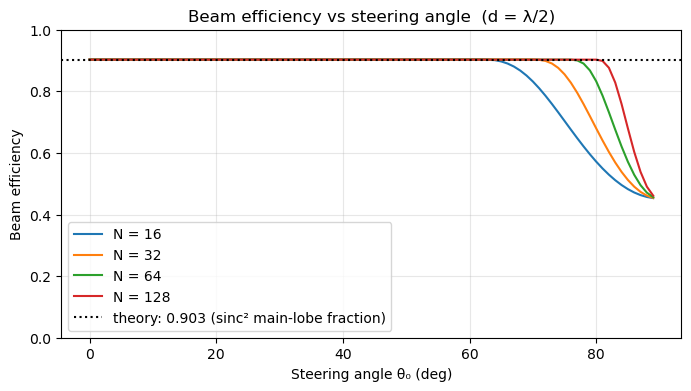

In [11]:
steer = np.arange(0, 90, 1)
fig, ax = plt.subplots(figsize=(8, 4))
for n in [16, 32, 64, 128]:
    eff = [power_budget(np.arange(n) * d, wl, theta0_deg=s)["beam_eff"] for s in steer]
    ax.plot(steer, eff, label=f"N = {n}")
ax.axhline(0.903, color="k", ls=":", label="theory: 0.903 (sinc² main-lobe fraction)")
ax.set_xlabel("Steering angle θ₀ (deg)"); ax.set_ylabel("Beam efficiency")
ax.set_ylim(0, 1); ax.set_title("Beam efficiency vs steering angle  (d = λ/2)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Notes:** We get 90 % beam efficiency (save for extreme angles). This is explained by the fact that a uniform array's main lobe is a sinc^2. In a sinc^2 function, 90.3 % of its area lies between its first nulls. 

At extreme angles, part of the main lobe slides past visible edge (at +- 90deg). Narrower main lobes for larger arrays, hence they keep their beam efficiencies out to large 